# 02 - GeoTIFF, CRS and a mock hyperspectral cube

## 1. What a GeoTIFF adds to an array

A NumPy cube only knows `(row, column, band)`. A GeoTIFF also stores **where on Earth** each pixel is:

- **CRS** (coordinate reference system): the "language" of the coordinates.
- **Affine transform**: the six numbers that turn `(column, row)` into `(x, y)` in that CRS.

| CRS | Units | Used for |
|---|---|---|
| `EPSG:4326` (WGS84) | degrees (lon/lat) | GPS, GeoJSON, "where is this?" |
| `EPSG:32643` (UTM zone 43N) | **metres** | measuring: a 30 m pixel really is 30 m |
| `EPSG:3857` (Web Mercator) | metres (distorted) | drawing on web maps |

We store the cube in **UTM** because distances and areas (pixels, acres) are in metres. Convert to lon/lat only when you need to.

```
transform = Affine(30, 0, west,
                    0, -30, north)
```

The `-30` is not a typo: row numbers grow **downwards**, but northing grows **upwards**. The `(west, north)` pair is the **upper-left corner** of the upper-left pixel (not its centre).

Rasterio also uses **bands first**, `(B, H, W)`, and numbers bands from **1**, not 0. Our in-memory convention stays `(H, W, B)` from notebook 01.

## 2. Imports and paths

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.transform import from_origin, xy, rowcol
from rasterio.warp import transform as warp_transform, transform_bounds
from rasterio.windows import Window
from scipy.ndimage import gaussian_filter

plt.rcParams["figure.dpi"] = 110

REPO_ROOT = Path(".") if Path("notebooks").is_dir() else Path("..")
MOCK_DIR = REPO_ROOT / "data" / "mock"
FIG_DIR = REPO_ROOT / "reports" / "figures"
MOCK_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    print("saved", FIG_DIR / name)

## 3. Where is the mock farm?

We choose a grid of 67 x 67 pixels at 30 m, which is about **1,000 acres**, the size of farm from our use case. The location is arbitrary (somewhere in northern India, UTM zone 43N); only the numbers matter.

In [2]:
H = W = 67               # pixels
B = 200                  # spectral bands (same count as Indian Pines)
PIXEL_M = 30             # metres per pixel
CRS = "EPSG:32643"       # UTM zone 43N, units = metres
WEST, NORTH = 550_000, 3_460_000   # upper-left corner, in UTM metres

transform = from_origin(WEST, NORTH, PIXEL_M, PIXEL_M)
print(transform)

EAST, SOUTH = WEST + W * PIXEL_M, NORTH - H * PIXEL_M
lon_w, lat_s, lon_e, lat_n = transform_bounds(CRS, "EPSG:4326", WEST, SOUTH, EAST, NORTH)

print()
print(f"extent: {W * PIXEL_M} m x {H * PIXEL_M} m")
print(f"area  : {H * W * PIXEL_M ** 2 / 4046.856:.0f} acres")
print(f"lon/lat corners: ({lon_w:.4f}, {lat_s:.4f}) to ({lon_e:.4f}, {lat_n:.4f})")

| 30.00, 0.00, 550000.00|
| 0.00,-30.00, 3460000.00|
| 0.00, 0.00, 1.00|

extent: 2010 m x 2010 m
area  : 998 acres
lon/lat corners: (75.5251, 31.2550) to (75.5464, 31.2732)


## 4. A simple physical model of vegetation spectra

We build each pixel's spectrum from the features real crop spectra show:

- **Visible:** chlorophyll absorbs blue and red light, so reflectance is low, with a small bump in green (~550 nm).
- **Red edge (~700-750 nm):** a steep jump from low visible to high near-infrared (NIR) reflectance.
- **NIR plateau:** high reflectance from healthy leaf structure, falling slowly into the short-wave infrared (SWIR).
- **Water absorption dips** near 970, 1200, 1450 and 1940 nm.

A single number, `stress` (0 = healthy, 1 = badly stressed), changes the spectrum the way crop stress typically does: **less chlorophyll** (higher visible reflectance), **red edge shifts to shorter wavelengths**, **lower NIR plateau**, and a **little less water absorption**.

This is a mock, not a calibrated model of any specific disease. The point is a clear, known signal.

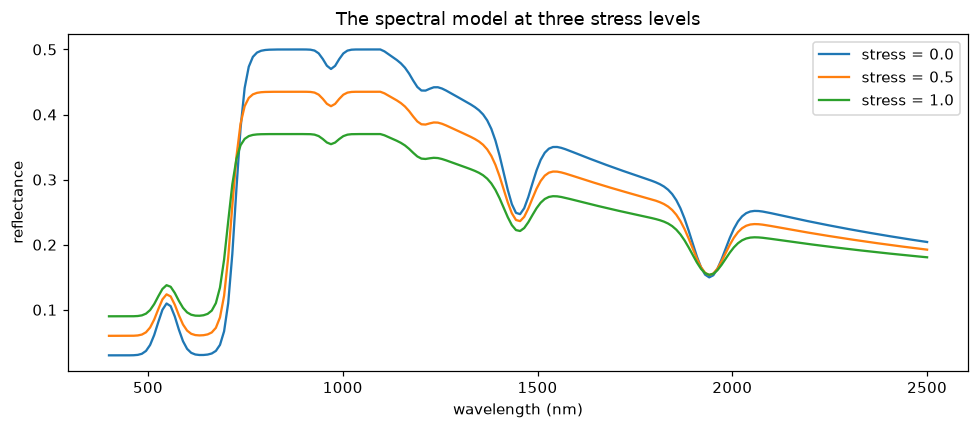

In [3]:
wavelengths = np.linspace(400, 2500, B)      # nm


def vegetation_spectrum(stress):
    # stress: array of any shape with values in [0, 1] -> reflectance with a trailing band axis
    s = np.asarray(stress, dtype=np.float64)[..., None]

    green_bump = 0.08 * np.exp(-((wavelengths - 550) / 35) ** 2)
    visible = 0.03 + 0.06 * s + green_bump * (1 - 0.4 * s)       # stress -> more visible reflectance

    red_edge = 725 - 20 * s                                       # stress -> red edge moves to shorter wavelengths
    step = 1 / (1 + np.exp(-(wavelengths - red_edge) / 12))       # smooth jump from visible to NIR

    nir = 0.50 - 0.18 * s                                         # stress -> lower NIR plateau
    fall_off = np.exp(-np.clip(wavelengths - 1100, 0, None) / 900)
    long_wave = nir * (0.25 + 0.75 * fall_off) + 0.05 * s         # NIR plateau fades into SWIR

    refl = visible * (1 - step) + long_wave * step

    for centre, width, depth in ((970, 25, 0.06), (1200, 30, 0.05), (1450, 50, 0.35), (1940, 60, 0.45)):
        refl = refl * (1 - depth * (1 - 0.3 * s) * np.exp(-((wavelengths - centre) / width) ** 2))

    return np.clip(refl, 0.01, 0.95)


fig, ax = plt.subplots(figsize=(9, 4))
for s in (0.0, 0.5, 1.0):
    ax.plot(wavelengths, vegetation_spectrum(s), label=f"stress = {s}")
ax.set_xlabel("wavelength (nm)")
ax.set_ylabel("reflectance")
ax.set_title("The spectral model at three stress levels")
ax.legend()
fig.tight_layout()
plt.show()

## 5. Build the cube

1. Every pixel gets a **small, smooth, random stress** (natural field variation), so healthy pixels are not identical.
2. One **disk-shaped patch** of 21 pixels (about 5 acres) gets high stress: strongest in the middle, weaker at the edge, so the edge is a bit ambiguous like real life.
3. The **label map** marks the patch: `1` = stressed, `0` = healthy.
4. We add smooth brightness variation (light and shadow) and random sensor noise.

A fixed random seed makes the cube **identical every time** you run the notebook.

In [4]:
rng = np.random.default_rng(42)
yy, xx = np.mgrid[:H, :W]


def smooth_field(sigma):
    f = gaussian_filter(rng.normal(size=(H, W)), sigma)
    return (f - f.mean()) / f.std()


stress = np.clip(0.06 + 0.04 * smooth_field(6), 0, None)       # gentle background variation

CY, CX, RADIUS = 38, 22, 2.7                                   # patch centre (row, col) and radius in pixels
dist = np.hypot(yy - CY, xx - CX)
patch = dist <= RADIUS
stress[patch] = 0.9 - 0.4 * dist[patch] / RADIUS + rng.normal(0, 0.03, patch.sum())
stress = np.clip(stress, 0, 1)
labels = patch.astype(np.uint8)                                # 1 = stressed, 0 = healthy

brightness = 1 + 0.03 * smooth_field(10)                       # +-3% light / shadow
cube = vegetation_spectrum(stress) * brightness[..., None]
cube = cube + rng.normal(0, 0.008, cube.shape)                 # sensor noise
cube = np.clip(cube, 0, 1).astype(np.float32)                  # (H, W, B) float32 reflectance

print("cube:", cube.shape, cube.dtype, f"| {cube.nbytes / 1e6:.1f} MB")
print(f"stressed patch: {int(labels.sum())} pixels = {labels.sum() * PIXEL_M ** 2 / 4046.856:.1f} acres")
print(f"mean stress  healthy: {stress[labels == 0].mean():.2f} | patch: {stress[labels == 1].mean():.2f}")

cube: (67, 67, 200) float32 | 3.6 MB
stressed patch: 21 pixels = 4.7 acres
mean stress  healthy: 0.06 | patch: 0.64


## 6. Look at the result

Left: mean spectrum of healthy vs stressed pixels (the shaded band is +-1 standard deviation). Right: one NIR band, where the stressed patch is darker. This is the signal a model has to find.

saved ..\reports\figures\mock_cube_overview.png


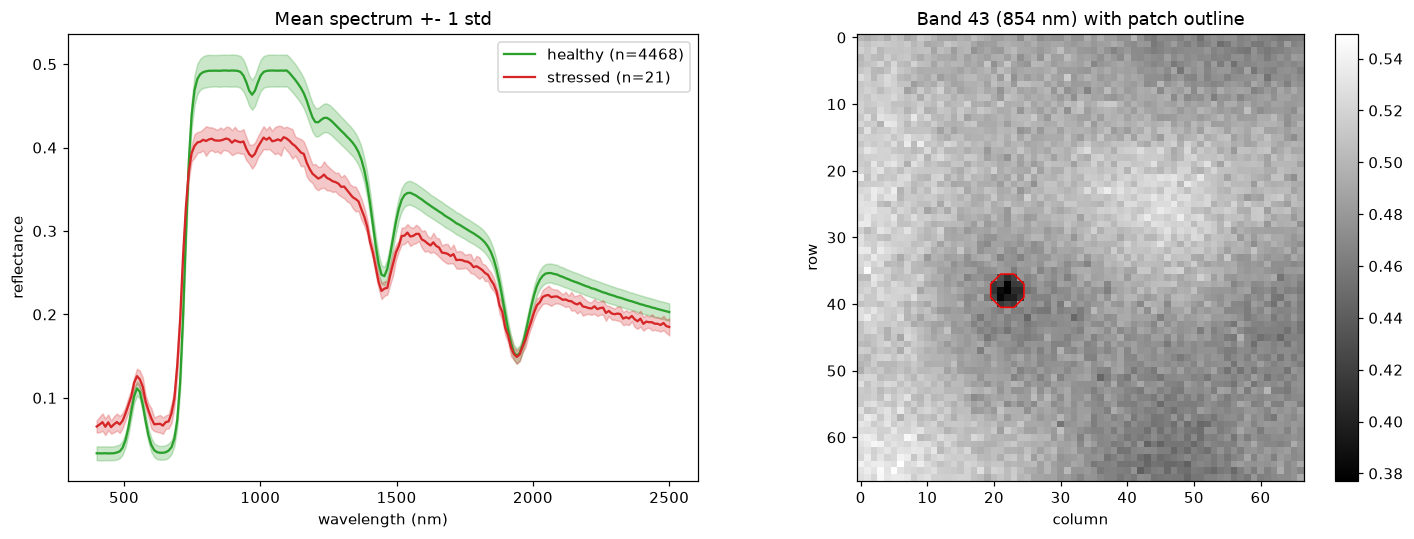

In [5]:
healthy_px = cube[labels == 0]       # (n_healthy, B)
stressed_px = cube[labels == 1]      # (n_stressed, B)
b_nir = int(np.argmin(np.abs(wavelengths - 850)))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for px, name, colour in ((healthy_px, "healthy", "tab:green"), (stressed_px, "stressed", "tab:red")):
    m, sd = px.mean(axis=0), px.std(axis=0)
    axes[0].plot(wavelengths, m, color=colour, label=f"{name} (n={len(px)})")
    axes[0].fill_between(wavelengths, m - sd, m + sd, color=colour, alpha=0.25)
axes[0].set_xlabel("wavelength (nm)")
axes[0].set_ylabel("reflectance")
axes[0].set_title("Mean spectrum +- 1 std")
axes[0].legend()

im = axes[1].imshow(cube[:, :, b_nir], cmap="gray")
axes[1].contour(labels, levels=[0.5], colors="red", linewidths=1)
axes[1].set_title(f"Band {b_nir} ({wavelengths[b_nir]:.0f} nm) with patch outline")
axes[1].set_xlabel("column")
axes[1].set_ylabel("row")
fig.colorbar(im, ax=axes[1], fraction=0.046)

fig.tight_layout()
save_fig(fig, "mock_cube_overview.png")
plt.show()

## 7. Write the GeoTIFFs

Two files:

- `mock_cube.tif`: the 200-band cube. Rasterio wants `(bands, H, W)`, so we transpose, the same trick as the `chw` view in notebook 01.
- `mock_labels.tif`: the 1-band label map, for training later.

We store each band's wavelength in the band description and all wavelengths in one tag so we never lose which band is which. `compress="deflate"` shrinks the file without losing any values.

In [6]:
cube_path = MOCK_DIR / "mock_cube.tif"
labels_path = MOCK_DIR / "mock_labels.tif"

profile = dict(driver="GTiff", height=H, width=W, crs=CRS, transform=transform, compress="deflate")

with rasterio.open(cube_path, "w", count=B, dtype="float32", **profile) as dst:
    dst.write(np.transpose(cube, (2, 0, 1)))                    # (H, W, B) -> (B, H, W)
    for i, w in enumerate(wavelengths, start=1):                # bands are numbered from 1
        dst.set_band_description(i, f"{w:.1f} nm")
    dst.update_tags(wavelengths_nm=",".join(f"{w:.2f}" for w in wavelengths))

with rasterio.open(labels_path, "w", count=1, dtype="uint8", **profile) as dst:
    dst.write(labels, 1)

print(f"{cube_path.name}: {cube_path.stat().st_size / 1e6:.2f} MB")
print(f"{labels_path.name}: {labels_path.stat().st_size / 1e3:.1f} KB")

mock_cube.tif: 3.19 MB
mock_labels.tif: 0.4 KB


## 8. Read it back and check

Never trust a write you have not read back. We check the georeferencing, then that the values are **exactly** what we wrote. Remember: Rasterio bands start at **1**, so band 51 is `cube[:, :, 50]`.

In [7]:
with rasterio.open(cube_path) as src:
    print("size       :", src.width, "x", src.height, "| bands:", src.count, "| dtype:", src.dtypes[0])
    print("CRS        :", src.crs)
    print("pixel size :", src.res)
    print("bounds     :", src.bounds)
    print("band 1 / 100:", src.descriptions[0], "/", src.descriptions[99])

    back = src.read()                                           # (B, H, W)
    band_51 = src.read(51)                                      # one band: (H, W)
    window = src.read(window=Window(col_off=10, row_off=30, width=16, height=16))   # only a 16 x 16 piece

print()
print("lossless round trip          :", np.array_equal(back, np.transpose(cube, (2, 0, 1))))
print("band 51 equals cube[:, :, 50]:", np.array_equal(band_51, cube[:, :, 50]))
print("window shape (B, h, w)       :", window.shape)

size       : 67 x 67 | bands: 200 | dtype: float32
CRS        : EPSG:32643
pixel size : (30.0, 30.0)
bounds     : BoundingBox(left=550000.0, bottom=3457990.0, right=552010.0, top=3460000.0)
band 1 / 100: 400.0 nm / 1444.7 nm

lossless round trip          : True
band 51 equals cube[:, :, 50]: True
window shape (B, h, w)       : (200, 16, 16)


## 9. Pixels to coordinates and back

Two conversions you will use constantly:

- `transform * (col, row)` gives the **upper-left corner** of a pixel.
- `xy(..., offset="center")` gives its **centre**, 15 m further east and 15 m further south.

Mixing up corner and centre shifts everything by half a pixel. That is exactly the kind of error the GIS validation step later is designed to catch.

In [8]:
with rasterio.open(cube_path) as src:
    row, col = CY, CX                                           # the centre pixel of our stressed patch

    corner_x, corner_y = src.transform * (col, row)
    centre_x, centre_y = xy(src.transform, row, col, offset="center")
    back_row, back_col = rowcol(src.transform, centre_x, centre_y)

    lon, lat = warp_transform(src.crs, "EPSG:4326", [centre_x], [centre_y])

print(f"pixel (row {row}, col {col})")
print(f"  upper-left corner : x={corner_x:.1f}, y={corner_y:.1f}")
print(f"  centre            : x={centre_x:.1f}, y={centre_y:.1f}   (+{PIXEL_M / 2:.0f} m east, -{PIXEL_M / 2:.0f} m north)")
print(f"  back to row/col   : ({back_row}, {back_col})")
print(f"  lon/lat of centre : ({lon[0]:.5f}, {lat[0]:.5f})")

pixel (row 38, col 22)
  upper-left corner : x=550660.0, y=3458860.0
  centre            : x=550675.0, y=3458845.0   (+15 m east, -15 m north)
  back to row/col   : (38, 22)
  lon/lat of centre : (75.53228, 31.26276)


## 10. A georeferenced picture

Now the axes are real **UTM coordinates in metres** read from the file, not row and column numbers. `extent` tells Matplotlib where the image sits in the world.

saved ..\reports\figures\mock_cube_georef.png


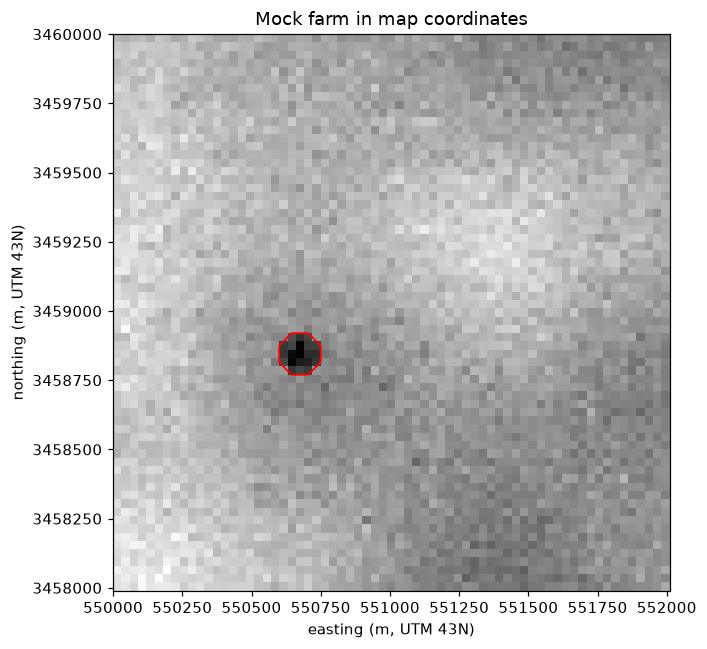

In [9]:
with rasterio.open(cube_path) as src:
    left, bottom, right, top = src.bounds
    nir_band = src.read(b_nir + 1)                              # +1 because Rasterio counts from 1

with rasterio.open(labels_path) as src:
    lab = src.read(1)

xs = left + (np.arange(W) + 0.5) * PIXEL_M                      # pixel-centre coordinates
ys = top - (np.arange(H) + 0.5) * PIXEL_M

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.imshow(nir_band, cmap="gray", extent=(left, right, bottom, top))
ax.contour(xs, ys, lab, levels=[0.5], colors="red", linewidths=1.2)
ax.set_xlabel("easting (m, UTM 43N)")
ax.set_ylabel("northing (m, UTM 43N)")
ax.set_title("Mock farm in map coordinates")
ax.ticklabel_format(style="plain")
fig.tight_layout()
save_fig(fig, "mock_cube_georef.png")
plt.show()

## Takeaways

- A GeoTIFF = pixel values + **CRS** + **affine transform**. The transform's `(west, north)` is the upper-left **corner** of the first pixel.
- Use a **metric CRS (UTM)** for anything you measure; convert to lon/lat only for display or GeoJSON.
- Rasterio: **bands first** `(B, H, W)` and **bands numbered from 1**. In memory we keep `(H, W, B)`.
- Always **read back and compare** after writing.
- The mock cube has a known answer (21 stressed pixels, about 5 acres), so we can check models against the truth.

**Next:** save this same cube as **HDF5** and write one `load_cube()` that opens either format.